# Módulo 28 · Práctica: LLM como optimizadores y del prototipo a la producción

Este cuaderno implementa, paso a paso, los **casos de estudio** de los apuntes del módulo 28. No llama a ninguna API externa: donde el método original usa un LLM, el cuaderno lo sustituye por un generador de propuestas explícito y lo dice. Todos los datos son sintéticos y se generan aquí con semillas fijas; todos los números que aparecen en los apuntes se reproducen y se comprueban.

| Parte | Caso de los apuntes | Qué se hace |
| --- | --- | --- |
| 0 | — | Preparación y bibliotecas |
| 1 | Tema 1 · empaquetado en línea | Cota $L_1$, *first fit* y *best fit*, búsqueda evolutiva de una regla de prioridad al estilo FunSearch con un generador de mutaciones de programas, prueba de robustez |
| 2 | Tema 2 · instrucciones y código | Maldición del ganador, optimizador tipo OPRO sobre un espacio sintético de instrucciones, número óptimo de muestras de la autoconsistencia, Amdahl y medias geométricas |
| 3 | Tema 3 · AutoML | Gemelo de la línea de envasado, espacio CASH de tres familias, halving sucesivo frente a búsqueda aleatoria |
| 4 | Tema 4 · mantenimiento predictivo | Clasificador de riesgo, Weibull con censura, política por edad, PSI, ponderación inversa, calendario semanal con un programa entero, cinco políticas en el gemelo |
| 5 | Tema 5 · valor y riesgo | Intervalos pareados y *bootstrap*, tamaño del piloto, VAN con Monte Carlo, CVaR |
| 6 | Tema 6 · guía | Techo de valor con un oráculo, mini-casos de la fábrica y del videojuego |
| 7 | — | Retos |

Las celdas marcadas con `# TU CÓDIGO` contienen la solución de referencia entre `# --- solución de referencia ---` y `# --- fin ---`: bórrala e inténtalo antes de mirarla. Cada ejercicio va seguido de una celda de **comprobación** con `assert`. Tiempo total de ejecución en una CPU: algo más de un minuto (unos 75 s en la máquina de referencia).

## Parte 0 · Preparación

In [1]:
# Dependencias: numpy, scipy, matplotlib y scikit-learn (no hace falta nada más).
# %pip install numpy scipy matplotlib scikit-learn
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")   # evita la sobresuscripción de hilos en máquinas pequeñas
import math, time, itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize, milp, LinearConstraint, Bounds, brentq
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
import scipy, sklearn
print("numpy", np.__version__, "· scipy", scipy.__version__, "· scikit-learn", sklearn.__version__)
T_INICIO = time.time()

numpy 2.5.3 · scipy 1.18.1 · scikit-learn 1.9.1


## Parte 1 · Empaquetado en línea y búsqueda evolutiva de programas (tema 1)

Un almacén agrupa paquetes en bandejas de capacidad $C=100$ a medida que llegan. Los tamaños siguen una Weibull de forma 3 y escala 45, truncada a enteros entre 1 y 100, como en los conjuntos Weibull de FunSearch. El **esqueleto** recorre los objetos, calcula las bandejas abiertas en las que cabe cada uno y añade siempre una bandeja vacía como candidata; coloca el objeto en la de mayor `prioridad(s, r)`, donde $r$ es la capacidad restante y $g=r-s$ el hueco que quedaría.

In [2]:
C = 100
def weibull_items(n, rng, k=3.0, lam=45.0, C=100):
    return np.clip(np.floor(lam * rng.weibull(k, n)), 1, C)

def pack(items, prio, C=100):
    '''Empaquetado en línea. Candidatos: bandejas abiertas con hueco suficiente + una bandeja vacía.
    prio(s, r) devuelve una puntuación por candidato (r = capacidad restante antes de colocar).'''
    rem = np.empty(len(items)); nab = 0
    for s in items:
        r = rem[:nab]
        idx = np.nonzero(r >= s)[0]
        cand = np.append(r[idx], C)
        sc = prio(s, cand)
        j = int(np.argmax(sc))
        if j == len(idx):
            rem[nab] = C - s; nab += 1
        else:
            rem[idx[j]] -= s
    return nab

**Ejercicio 1.** Escribe `cota_l1(items, C)` (lema 1.10: $\lceil\sum_j s_j/C\rceil$) y las prioridades `prio_ff(s, r)` (*first fit*: menos el índice del candidato; `argmax` desempata por el primero) y `prio_bf(s, r)` (*best fit*: menos el hueco). Comprueba el ejemplo 1.12 de los apuntes: con $C=10$ y objetos $5,8,6,2,4,4,7$, FF usa 5 bandejas y BF 4.

In [3]:
# TU CÓDIGO
# --- solución de referencia ---
def cota_l1(items, C=100):
    return int(np.ceil(np.sum(items) / C))
prio_ff = lambda s, r: -np.arange(len(r), dtype=float)
prio_bf = lambda s, r: -(r - s)
# --- fin ---

In [4]:
# Comprobación
ej = np.array([5, 8, 6, 2, 4, 4, 7.])
assert cota_l1(ej, 10) == 4
assert pack(ej, prio_ff, C=10) == 5 and pack(ej, prio_bf, C=10) == 4
print("Correcto. Ejemplo 1.12: L1 = 4, FF = 5, BF = 4")

Correcto. Ejemplo 1.12: L1 = 4, FF = 5, BF = 4


### 1.1 Programas como árboles de expresiones

Las reglas candidatas son expresiones sobre $s$, $r$, $g$, constantes y escalones $[g\le c]$, con operaciones $+,-,\times,/$ (protegida), $\min$, $\max$, cuadrado, raíz, $1/(1+|x|)$ y $e^{-x/10}$. Un programa es una tupla anidada, por ejemplo `('neg', ('g',))` es *best fit*.

In [5]:
TERM = ['s', 'r', 'g']
UN = ['neg', 'sq', 'sqrt', 'inv', 'exp-']
BIN = ['+', '-', '*', '/', 'min', 'max']
def ev(t, s, r):
    k = t[0]
    if k == 'c': return np.full_like(r, t[1])
    if k == 's': return np.full_like(r, s)
    if k == 'r': return r
    if k == 'g': return r - s
    if k == 'step': return ((r - s) <= t[1]).astype(float)
    if k in UN:
        a = ev(t[1], s, r)
        if k == 'neg': return -a
        if k == 'sq': return a * a
        if k == 'sqrt': return np.sqrt(np.abs(a))
        if k == 'inv': return 1.0 / (np.abs(a) + 1.0)
        if k == 'exp-': return np.exp(-np.clip(a, -50, 50) / 10.0)
    a = ev(t[1], s, r); b = ev(t[2], s, r)
    if k == '+': return a + b
    if k == '-': return a - b
    if k == '*': return a * b
    if k == '/': return a / (np.abs(b) + 1e-6) * np.sign(b + 1e-12)
    if k == 'min': return np.minimum(a, b)
    if k == 'max': return np.maximum(a, b)
    raise ValueError(k)

def txt(t):
    k = t[0]
    if k == 'c': return f"{t[1]:.3g}"
    if k in TERM: return k
    if k == 'step': return f"[g<={t[1]:.3g}]"
    if k == 'neg': return f"-({txt(t[1])})"
    if k == 'sq': return f"({txt(t[1])})^2"
    if k == 'sqrt': return f"sqrt|{txt(t[1])}|"
    if k == 'inv': return f"1/(1+|{txt(t[1])}|)"
    if k == 'exp-': return f"exp(-{txt(t[1])}/10)"
    if k in ('min', 'max'): return f"{k}({txt(t[1])}, {txt(t[2])})"
    return f"({txt(t[1])} {k} {txt(t[2])})"

def size(t): return 1 + sum(size(c) for c in t[1:] if isinstance(c, tuple))
def nodes(t, path=()):
    yield path, t
    for i, c in enumerate(t[1:], 1):
        if isinstance(c, tuple): yield from nodes(c, path + (i,))
def replace(t, path, new):
    if not path: return new
    l = list(t); l[path[0]] = replace(t[path[0]], path[1:], new); return tuple(l)
def rand_tree(rng, d=2):
    if d == 0 or rng.random() < 0.3:
        u = rng.random()
        if u < 0.55: return (TERM[rng.integers(3)],)
        if u < 0.8: return ('c', float(np.round(rng.normal(0, 3), 2)))
        return ('step', float(rng.integers(0, 15)))
    if rng.random() < 0.3: return (UN[rng.integers(len(UN))], rand_tree(rng, d - 1))
    return (BIN[rng.integers(len(BIN))], rand_tree(rng, d - 1), rand_tree(rng, d - 1))
print(txt(('+', ('neg', ('min', ('g',), ('c', 9.0))), ('*', ('c', -5.82), ('step', 20.0)))))

(-(min(g, 9)) + (-5.82 * [g<=20]))


### 1.2 El sustituto del LLM y el bucle de FunSearch

En FunSearch, el LLM recibe $k=2$ programas ordenados de peor a mejor y escribe una versión «mejorada». Aquí, `propone` hace ese papel con ediciones que imitaría un programador: retocar una constante o un umbral, añadir una regla «si el hueco es pequeño, suma $w$», saturar el hueco ($g\to\min(g,c)$ o $\max(g,c)$), reescribir un subárbol o combinar las dos funciones del *prompt*. El evaluador ejecuta el programa y devuelve menos el número medio de bandejas ($-\infty$ si falla). La base de programas tiene 4 islas; dentro de cada una, las puntuaciones distintas hacen de *clusters* y se muestrean con una softmax de temperatura sobre puntuaciones normalizadas; dentro de un cluster se prefiere el programa más corto; cada 75 evaluaciones se reinicia la mitad peor de las islas con el mejor programa de una superviviente.

**Ejercicio 2.** Escribe `softmax_normalizada(s, T)`: $z_i=(s_i-\max s)/(\max s-\min s)$ y $p_i\propto e^{z_i/T}$. Compruébala con el ejercicio 1.2(b) de los apuntes.

In [6]:
# TU CÓDIGO
# --- solución de referencia ---
def softmax_normalizada(s, T):
    s = np.asarray(s, float)
    z = (s - s.max()) / ((s.max() - s.min() + 1e-9) * T)
    p = np.exp(z) + 1e-12
    return p / p.sum()
# --- fin ---

In [7]:
# Comprobación
p = softmax_normalizada([-416.7, -409.3, -405.3], 0.3)
assert np.allclose(p, [0.0265, 0.2307, 0.7428], atol=5e-4)
print("Correcto:", p.round(4))

Correcto: [0.0265 0.2307 0.7428]


In [8]:
def propone(padres, rng):
    '''Sustituto del LLM: a partir de k=2 programas (de peor a mejor) genera una variante.'''
    best = padres[-1]
    u = rng.random()
    if u < 0.30:                                   # retocar una constante o un umbral
        cs = [(p, n) for p, n in nodes(best) if n[0] in ('c', 'step')]
        if cs:
            p, n = cs[rng.integers(len(cs))]
            v = n[1] + rng.normal(0, 1 + 0.2 * abs(n[1]))
            if n[0] == 'step': v = float(max(0, round(v)))
            return replace(best, p, (n[0], float(np.round(v, 2))))
    if u < 0.55:                                   # añadir una regla sobre el hueco
        w = float(rng.choice([1, 2, 5, 10, 20]) * rng.choice([-1, 1]))
        return ('+', best, ('*', ('c', w), ('step', float(rng.integers(0, 16)))))
    if u < 0.70:                                   # saturar el hueco
        gs = [p for p, n in nodes(best) if n[0] == 'g']
        if gs:
            op = 'min' if rng.random() < 0.5 else 'max'
            return replace(best, gs[rng.integers(len(gs))], (op, ('g',), ('c', float(rng.integers(1, 20)))))
    if u < 0.85:                                   # reescribir un subárbol
        ps = list(nodes(best)); p, _ = ps[rng.integers(len(ps))]
        return replace(best, p, rand_tree(rng, 2))
    a = float(np.round(rng.uniform(0.2, 1), 2))    # combinar las dos funciones del «prompt»
    return ('+', best, ('*', ('c', a), padres[0]))

def puntua(t, insts):
    '''Evaluador: menos el número medio de bandejas. Programas inválidos: -inf.'''
    try:
        with np.errstate(all='ignore'):
            prio = lambda s, r: np.nan_to_num(ev(t, s, r), nan=-1e9, posinf=1e9, neginf=-1e9)
            return -np.mean([pack(it, prio) for it in insts])
    except Exception:
        return -np.inf

cache = {}
def funsearch(train, budget=300, n_islas=4, T0=0.3, reinicio=75, seed=0, max_size=40):
    rng = np.random.default_rng(seed)
    semilla = ('neg', ('g',))                      # programa semilla: best fit
    s0 = puntua(semilla, train)
    islas = [[(s0, semilla)] for _ in range(n_islas)]
    hist = []; best = (s0, semilla); n = 0
    while n < budget:
        isl = islas[rng.integers(n_islas)]
        sc = np.array(sorted({p[0] for p in isl}))                  # «clusters»
        pr = softmax_normalizada(sc, T0)
        ch = rng.choice(len(sc), size=min(2, len(sc)), replace=False, p=pr) if len(sc) > 1 else [0, 0]
        par = [min([p for p in isl if p[0] == sc[c]], key=lambda p: size(p[1]))[1] for c in ch]
        if len(par) == 1: par = par * 2
        par.sort(key=lambda t: cache.get(t, -np.inf))                 # de peor a mejor
        hijo = propone(par, rng)
        if size(hijo) > max_size: continue
        sh = puntua(hijo, train); cache[hijo] = sh; n += 1
        if np.isfinite(sh): isl.append((sh, hijo))
        if sh > best[0]: best = (sh, hijo)
        hist.append(best[0])
        if n % reinicio == 0:                                         # reinicio de la mitad peor
            mejores = [max(p[0] for p in i) for i in islas]
            orden = np.argsort(mejores)
            for j in orden[:n_islas // 2]:
                donante = islas[orden[-1 - rng.integers(n_islas // 2)]]
                islas[j] = [max(donante, key=lambda p: p[0])]
    return best, hist

### 1.3 Ejecución (unos 30 s)

Entrenamiento: 3 instancias de 1000 objetos. Prueba: 5 instancias nuevas de 5000 objetos. Presupuesto: 300 evaluaciones.

28.7 s · mejor puntuación de entrenamiento -405.33 · programa: (-(min(g, 9)) + (-5.82 * [g<=20]))


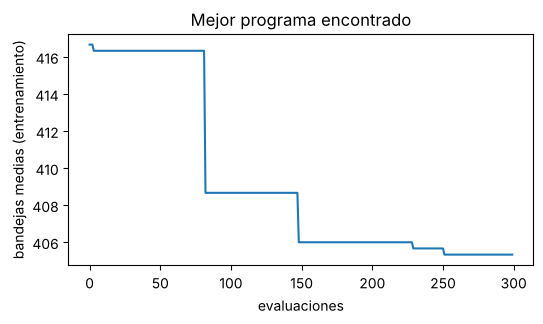

In [9]:
rng = np.random.default_rng(2024)
train = [weibull_items(1000, rng) for _ in range(3)]
test = [weibull_items(5000, rng) for _ in range(5)]
t0 = time.time()
cache.clear()
mejor, hist = funsearch(train, budget=300, seed=2)
print(f"{time.time() - t0:.1f} s · mejor puntuación de entrenamiento {mejor[0]:.2f} · programa: {txt(mejor[1])}")
plt.figure(figsize=(6, 3)); plt.plot(-np.array(hist)); plt.xlabel("evaluaciones"); plt.ylabel("bandejas medias (entrenamiento)")
plt.title("Mejor programa encontrado"); plt.show()

**Ejercicio 3.** Escribe a mano la regla encontrada, $\pi^*(s,r)=-\min(g,9)-5{,}82\,[g\le 20]$, como `prio_evo(s, r)` con operaciones de numpy, y calcula el exceso sobre $L_1$ de FF, BF y $\pi^*$ en las instancias de prueba. Guarda los excesos (en %) en el diccionario `exceso`.

In [10]:
# TU CÓDIGO
# --- solución de referencia ---
prio_evo = lambda s, r: -np.minimum(r - s, 9) - 5.82 * ((r - s) <= 20)
lb = np.mean([cota_l1(it) for it in test])
bandejas = {nm: np.mean([pack(it, p) for it in test]) for nm, p in [("FF", prio_ff), ("BF", prio_bf), ("evolucionada", prio_evo)]}
exceso = {nm: 100 * (b - lb) / lb for nm, b in bandejas.items()}
# --- fin ---

In [11]:
# Comprobación
assert txt(mejor[1]) == "(-(min(g, 9)) + (-5.82 * [g<=20]))", "Con la semilla 2 se obtiene la regla de los apuntes"
assert np.isclose(lb, 1985.6)
assert np.isclose(bandejas["FF"], 2073.4) and np.isclose(bandejas["BF"], 2064.8) and np.isclose(bandejas["evolucionada"], 2011.2)
print("Correcto. L1 medio =", lb, "· excesos (%):", {k: round(v, 3) for k, v in exceso.items()})

Correcto. L1 medio = 1985.6 · excesos (%): {'FF': np.float64(4.422), 'BF': np.float64(3.989), 'evolucionada': np.float64(1.289)}


### 1.4 La heurística publicada por FunSearch y la prueba de robustez

El repositorio oficial de FunSearch (licencia Apache 2.0) publica la heurística que encontró para los datos Weibull. Su esqueleto trata todas las bandejas, vacías incluidas, como un único vector, así que se evalúa con un empaquetador fiel al original. Después se cambia la distribución (Weibull de escala 60: objetos más grandes) para ver si las reglas generalizan.

In [12]:
def pack_funsearch(items, C=100):
    '''Heurística de FunSearch para Weibull (repositorio google-deepmind/funsearch, Apache 2.0),
    con su esqueleto original: un vector con tantas bandejas como objetos.'''
    bins = np.full(len(items), float(C))
    for s in items:
        v = np.nonzero(bins - s >= 0)[0]; b = bins[v]
        score = (b - b.max())**2 / s + b**2 / s**2 + b**2 / s**3
        score[b > s] = -score[b > s]
        score[1:] -= score[:-1]
        bins[v[np.argmax(score)]] -= s
    return int((bins != C).sum())
nb_fs = np.mean([pack_funsearch(it) for it in test])
exceso["FunSearch publicada"] = 100 * (nb_fs - lb) / lb
assert np.isclose(nb_fs, 2000.0)
for k, v in exceso.items(): print(f"{k:22s} exceso {v:5.2f} %")

r2 = np.random.default_rng(9)
_ = [np.clip(np.floor(30 * r2.weibull(3, 5000)), 1, 100) for _ in range(5)]       # (consume la misma secuencia que en los apuntes)
otra = [np.clip(np.floor(60 * r2.weibull(3, 5000)), 1, 100) for _ in range(5)]
lb2 = np.mean([cota_l1(i) for i in otra])
rob = {nm: 100 * (np.mean([pack(i, p) for i in otra]) - lb2) / lb2 for nm, p in [("FF", prio_ff), ("BF", prio_bf), ("evolucionada", prio_evo)]}
rob["FunSearch publicada"] = 100 * (np.mean([pack_funsearch(i) for i in otra]) - lb2) / lb2
print("\nWeibull de escala 60:", {k: round(v, 2) for k, v in rob.items()})
assert rob["FunSearch publicada"] > rob["FF"] > rob["BF"], "La heurística publicada no generaliza a esta distribución"

FF                     exceso  4.42 %
BF                     exceso  3.99 %
evolucionada           exceso  1.29 %
FunSearch publicada    exceso  0.73 %



Weibull de escala 60: {'FF': np.float64(6.05), 'BF': np.float64(5.19), 'evolucionada': np.float64(5.21), 'FunSearch publicada': np.float64(6.4)}


## Parte 2 · Optimizar instrucciones, muestras y código (tema 2)

### 2.1 La maldición del ganador
Veinte instrucciones con la misma exactitud verdadera, $0{,}70$, se evalúan con $n=100$ ejemplos y se elige la de mayor puntuación (ejemplo 2.5).

**Ejercicio 4.** Escribe `sesgo_ganador(K, n, p, reps, rng)` que simule `reps` veces la elección y devuelva el sesgo medio $\mathbb E[\hat J_{\hat k}-J_{\hat k}]$. Compáralo con la cota $\sigma\sqrt{2\ln K}$ de la proposición 2.4.

In [13]:
# TU CÓDIGO
# --- solución de referencia ---
def sesgo_ganador(K, n, p, reps, rng):
    return (rng.binomial(n, p, (reps, K)).max(1) / n - p).mean()
# --- fin ---

In [14]:
# Comprobación
sesgo = sesgo_ganador(20, 100, 0.7, 20000, np.random.default_rng(1))
sigma = math.sqrt(0.7 * 0.3 / 100); cota = sigma * math.sqrt(2 * math.log(20))
assert 0.075 < sesgo < cota and np.isclose(cota, 0.112, atol=1e-3)
print(f"Correcto. Sesgo simulado {sesgo:.4f} · cota {cota:.4f}")

Correcto. Sesgo simulado 0.0835 · cota 0.1122


### 2.2 Un optimizador tipo OPRO sobre un espacio sintético de instrucciones (ejemplo 2.7)

La instrucción para clasificar partes de avería combina seis decisiones (432 instrucciones). Su exactitud verdadera es una función sintética con interacciones. El optimizador guarda las 20 mejores (la «trayectoria», ordenada de peor a mejor), parte de una de las 3 mejores y cambia una o dos decisiones, eligiendo cada opción con una softmax de la puntuación media de las instrucciones de la trayectoria que la contienen: es un sustituto sencillo de lo que un LLM infiere al leer la trayectoria.

In [15]:
SLOTS = {"rol": ["ninguno", "técnico", "experto"], "formato": ["libre", "JSON", "una palabra"],
         "ejemplos": [0, 2, 4, 8], "razonamiento": ["no", "paso a paso", "síntomas primero"],
         "etiquetas": ["es", "en"], "orden": ["antes", "después"]}
names = list(SLOTS); sizes = [len(SLOTS[k]) for k in names]
EFF = {"rol": [0, .10, .15], "formato": [0, .35, .20], "ejemplos": [0, .30, .45, .50],
       "razonamiento": [0, .25, .40], "etiquetas": [0, -.10], "orden": [0, .05]}
def true_acc(p):
    z = -0.2 + sum(EFF[k][p[i]] for i, k in enumerate(names))
    if p[1] == 2 and p[3] > 0: z -= 0.45           # «una palabra» choca con razonar
    if p[2] == 3 and p[3] == 2: z -= 0.15           # demasiado largo
    return 1 / (1 + np.exp(-z)) * 0.95
ALL = list(itertools.product(*[range(s) for s in sizes]))
ACC = np.array([true_acc(p) for p in ALL])
print("instrucciones:", len(ALL), "· mejor exactitud verdadera", ACC.max().round(4), "· media", ACC.mean().round(4))
def evalua(p, n, rng): return rng.binomial(n, true_acc(p)) / n
def opro(budget, n_val, rng, per_step=8, keep=20):
    hist = {}
    for _ in range(per_step):
        p = tuple(rng.integers(s) for s in sizes); hist[p] = evalua(p, n_val, rng)
    while len(hist) < budget:
        top = sorted(hist.items(), key=lambda kv: kv[1])[-keep:]
        sc = np.array([v for _, v in top]); new = []
        for _ in range(per_step):
            p = list(top[-1 - rng.integers(min(3, len(top)))][0])
            for i in rng.choice(len(sizes), rng.integers(1, 3), replace=False):
                m = np.array([np.mean([v for q, v in top if q[i] == o]) if any(q[i] == o for q, _ in top) else sc.mean() for o in range(sizes[i])])
                w = np.exp((m - m.max()) / 0.03); p[i] = rng.choice(sizes[i], p=w / w.sum())
            p = tuple(p)
            if p not in hist and len(hist) + len(new) < budget: new.append(p)
        for p in new: hist[p] = evalua(p, n_val, rng)
        if not new:
            p = tuple(rng.integers(s) for s in sizes)
            if p not in hist: hist[p] = evalua(p, n_val, rng)
    best = max(hist, key=hist.get); return best, hist[best]
def aleatoria(budget, n_val, rng):
    idx = rng.choice(len(ALL), budget, replace=False); h = {ALL[i]: evalua(ALL[i], n_val, rng) for i in idx}
    best = max(h, key=h.get); return best, h[best]
rng = np.random.default_rng(0); R2 = {"opro": [], "aleatoria": []}
t0 = time.time()
for rep in range(200):
    for nm, f in [("opro", opro), ("aleatoria", aleatoria)]:
        b, v = f(96, 100, rng); R2[nm].append((v, true_acc(b)))
for nm in R2:
    a = np.array(R2[nm]); print(f"{nm:9s} validación {a[:, 0].mean():.3f} · verdadera {a[:, 1].mean():.3f} · optimismo {(a[:, 0] - a[:, 1]).mean():.3f}")
print(f"({time.time() - t0:.1f} s)")
a_o, a_a = np.array(R2["opro"]), np.array(R2["aleatoria"])
assert np.isclose(a_o[:, 1].mean(), 0.701, atol=1e-3) and np.isclose(a_a[:, 1].mean(), 0.692, atol=1e-3)
assert (a_o[:, 0] - a_o[:, 1]).mean() > 0.08

instrucciones: 432 · mejor exactitud verdadera 0.7301 · media 0.5796


opro      validación 0.791 · verdadera 0.701 · optimismo 0.090
aleatoria validación 0.774 · verdadera 0.692 · optimismo 0.082
(7.3 s)


### 2.3 Cuántas muestras votar

**Ejercicio 5.** Escribe `m_optimo(p, V, c)` con el corolario 2.9: avanza de $m$ a $m+2$ mientras $V\Delta_m\ge 2c$, con $\Delta_m=\binom{m}{(m-1)/2}(p(1-p))^{(m+1)/2}(2p-1)$. Devuelve $m^*$ y $P_{m^*}$.

In [16]:
# TU CÓDIGO
# --- solución de referencia ---
def m_optimo(p, V, c):
    m, P = 1, p
    while True:
        d = math.comb(m, (m - 1) // 2) * (p * (1 - p)) ** ((m + 1) // 2) * (2 * p - 1)
        if V * d < 2 * c: return m, P
        m, P = m + 2, P + d
# --- fin ---

In [17]:
# Comprobación (texto del tema 2 y ejercicio 2.4)
def P_voto(m, p): return sum(math.comb(m, j) * p**j * (1 - p)**(m - j) for j in range((m + 1) // 2, m + 1))
m1, P1 = m_optimo(0.65, 0.50, 0.01); m2, P2 = m_optimo(0.70, 0.20, 0.004)
assert (m1, m2) == (5, 5) and np.isclose(P1, P_voto(5, 0.65)) and np.isclose(P2, 0.83692)
best_bruto = max(range(1, 41, 2), key=lambda m: 0.5 * P_voto(m, 0.65) - 0.01 * m)
assert best_bruto == m1
print(f"Correcto. p=0,65: m*={m1}, P={P1:.4f} · p=0,70: m*={m2}, P={P2:.4f}")

Correcto. p=0,65: m*=5, P=0.7648 · p=0,70: m*=5, P=0.8369


### 2.4 Amdahl y la medida de tiempos

**Ejercicio 6.** Escribe `amdahl(fracciones, factores)` para varias partes aceleradas a la vez y `media_geometrica(x)`. Comprueba el ejemplo 2.11 (40 min, fracciones 0,55 y 0,25 aceleradas ×4 y ×5) y el ejercicio 2.6.

In [18]:
# TU CÓDIGO
# --- solución de referencia ---
def amdahl(fracciones, factores):
    f = np.asarray(fracciones, float); a = np.asarray(factores, float)
    return 1.0 / ((1 - f.sum()) + (f / a).sum())
def media_geometrica(x):
    return float(np.exp(np.mean(np.log(x))))
# --- fin ---

In [19]:
# Comprobación
assert np.isclose(amdahl([0.55], [4]), 1 / 0.5875) and np.isclose(amdahl([0.55, 0.25], [4, 5]), 1 / 0.3875)
tA = np.array([2, 4, 1, 8, 3.]); tB = np.array([1.6, 4.4, 0.5, 8, 2.4])
gBA, gAB = media_geometrica(tB / tA), media_geometrica(tA / tB)
assert np.isclose(gBA * gAB, 1) and not np.isclose(np.mean(tB / tA) * np.mean(tA / tB), 1)
print(f"Correcto. Servicio: {40 / amdahl([0.55, 0.25], [4, 5]):.1f} min · media geométrica B/A = {gBA:.4f}")
print("P(Bin(20, 1/2) >= 15) =", round(stats.binom.sf(14, 20, 0.5), 4), "· con 14 victorias:", round(stats.binom.sf(13, 20, 0.5), 4))

Correcto. Servicio: 15.5 min · media geométrica B/A = 0.8115
P(Bin(20, 1/2) >= 15) = 0.0207 · con 14 victorias: 0.0577


## Parte 3 · El gemelo de la línea de envasado y AutoML (tema 3)

### 3.1 El gemelo
Seis máquinas en serie. Cada día, la «salud» $h$ de cada máquina se degrada con un incremento gamma que depende de la carga; la probabilidad diaria de avería es $1-\exp(-(0{,}001+(h/110)^3))$. Los sensores miden vibración ($2+0{,}06h$ mm/s más ruido) y temperatura del rodamiento. Una intervención preventiva o una avería devuelven $h$ a 0. Costes: avería 9000 €, preventivo 1200 € en las ventanas de cambio de formato (lunes, miércoles y viernes) y 2000 € fuera de ellas.

Todo el azar de un escenario se genera de antemano (**números aleatorios comunes**): así dos políticas distintas se comparan con la misma «suerte».

In [20]:
MAQ = ["llenadora", "taponadora", "etiquetadora", "encajonadora", "paletizadora", "enfardadora"]
NM = len(MAQ)
RATE = np.array([1.0, 0.8, 0.6, 0.7, 0.5, 0.9])
CF, CP_V, CP_F = 9000.0, 1200.0, 2000.0
VENT = (0, 2, 4)
def hazard(h): return 1 - np.exp(-(0.001 + (h / 110.0) ** 3))

class Escenario:
    '''Números aleatorios comunes: todo el azar se genera de antemano y no depende de las decisiones.'''
    def __init__(self, dias, seed):
        r = np.random.default_rng(seed)
        self.load = 0.5 + 0.3 * np.sin(2 * np.pi * np.arange(dias) / 365) + r.normal(0, 0.05, dias)
        self.g = r.gamma(2.0, 1.0, (dias, NM)) / 2.0
        self.u = r.random((dias, NM))
        self.ev = r.normal(0, 0.35, (dias, NM)); self.eT = r.normal(0, 1.2, (dias, NM))
        self.h0 = r.uniform(0, 30, NM); self.a0 = r.integers(0, 40, NM).astype(float)

def simula(esc, politica, dias=None):
    '''politica(d, obs) -> vector booleano de intervenciones preventivas al empezar el día d.'''
    dias = dias or len(esc.load)
    h = esc.h0.copy(); age = esc.a0.copy(); obs = []; coste = np.zeros(dias)
    fallos = np.zeros((dias, NM), bool); mlog = np.zeros((dias, NM), bool)
    for d in range(dias):
        L = esc.load[d]
        v = 2.0 + 0.06 * h + esc.ev[d]; T = 38 + 0.12 * h + 4 * L + esc.eT[d]
        obs.append(np.column_stack([v, T, age.copy(), np.full(NM, L)]))
        m = politica(d, obs)
        coste[d] += m.sum() * (CP_V if d % 7 in VENT else CP_F)
        h[m] = 0; age[m] = 0; mlog[d] = m
        h += esc.g[d] * RATE * (0.6 + 0.8 * L); age += 1
        f = esc.u[d] < hazard(h); fallos[d] = f
        coste[d] += CF * f.sum(); h[f] = 0; age[f] = 0
    return coste, fallos, np.array(obs), mlog

def feats(obs):
    '''Vibración, temperatura, edad, carga, pendiente de la vibración en 2 días y tipo de máquina.'''
    O = np.asarray(obs); D = len(O)
    v = O[:, :, 0]; vm2 = np.vstack([v[:2], v[:-2]]) if D > 2 else v
    return np.concatenate([O, ((v - vm2) / 2)[..., None], np.eye(NM)[None].repeat(D, 0)], -1)

def etiquetas(F, H=7):
    return np.array([F[d:d + H].any(0) for d in range(len(F))])

pol_H = lambda d, obs: obs[-1][:, 2] >= 70          # política actual: preventivo cada 70 días
def historia(seeds, dias=730):
    out = []
    for s in seeds:
        e = Escenario(dias, seed=s); c, F, O, M = simula(e, pol_H); out.append((e, c, F, O, M))
    return out
H = historia([11, 12, 13]); Ht = historia([21])
print("averías/año por máquina:", dict(zip(MAQ, np.mean([h[2].sum(0) / 2 for h in H], 0).round(2))))
print("coste/año medio por línea:", round(np.mean([h[1].sum() / 2 for h in H])))

averías/año por máquina: {'llenadora': np.float64(8.5), 'taponadora': np.float64(6.83), 'etiquetadora': np.float64(4.83), 'encajonadora': np.float64(4.83), 'paletizadora': np.float64(2.5), 'enfardadora': np.float64(7.33)}
coste/año medio por línea: 328233


### 3.2 Datos con división temporal y espacio CASH

Entrenamiento: primeros 18 meses de las tres líneas; validación: los 6 siguientes; prueba: una cuarta línea. Tres familias: regresión logística, *gradient boosting* y bosque aleatorio; 27 configuraciones aleatorias.

In [21]:
cut = 540
def XY(hs, a, b):
    Z = np.concatenate([feats(h[3])[a:b] for h in hs], 1); y = np.concatenate([etiquetas(h[2])[a:b] for h in hs], 1)
    return Z.reshape(-1, Z.shape[-1]), y.ravel()
Xtr, ytr = XY(H, 0, cut - 7); Xva, yva = XY(H, cut, 723); Xte, yte = XY(Ht, 0, 723)
print("filas:", len(Xtr), len(Xva), len(Xte), "· tasa de positivos (entrenamiento):", round(ytr.mean(), 4))

def muestra(rng):
    a = rng.integers(3)
    if a == 0: return ("logística", dict(C=float(10 ** rng.uniform(-3, 2))))
    if a == 1: return ("gbm", dict(learning_rate=float(10 ** rng.uniform(-2, -0.5)), max_depth=int(rng.integers(2, 7)), max_iter=int(rng.integers(50, 400))))
    return ("bosque", dict(n_estimators=int(rng.integers(30, 150)), max_depth=int(rng.integers(3, 12)), min_samples_leaf=int(rng.integers(1, 30))))
def construye(cfg):
    k, h = cfg
    if k == "logística": return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, **h))
    if k == "gbm": return HistGradientBoostingClassifier(random_state=0, **h)
    return RandomForestClassifier(random_state=0, n_jobs=1, **h)
def entrena(cfg, frac):
    '''Fidelidad = fracción (la más reciente) de los datos de entrenamiento.'''
    n = int(len(Xtr) * frac); m = construye(cfg).fit(Xtr[-n:], ytr[-n:])
    return m, log_loss(yva, np.clip(m.predict_proba(Xva)[:, 1], 1e-6, 1 - 1e-6))
rng = np.random.default_rng(0); cfgs = [muestra(rng) for _ in range(27)]
t0 = time.time(); full = [entrena(c, 1.0)[1] for c in cfgs]; t_full = time.time() - t0
ib = int(np.argmin(full))
print(f"búsqueda aleatoria: {cfgs[ib]} · pérdida de validación {full[ib]:.4f} · {t_full:.1f} s")

filas: 9594 3294 4338 · tasa de positivos (entrenamiento): 0.1248


búsqueda aleatoria: ('bosque', {'n_estimators': 114, 'max_depth': 6, 'min_samples_leaf': 26}) · pérdida de validación 0.2378 · 9.3 s


**Ejercicio 7.** Escribe `halving_sucesivo(n_cfg, fracciones, eta, evalua)`: empieza con los índices `range(n_cfg)`; en cada escalón evalúa los supervivientes con `evalua(i, frac)` y conserva la fracción $1/\eta$ mejor (al menos 1). Devuelve el índice elegido y el coste en entrenamientos completos equivalentes, $\sum$ (supervivientes × fracción).

In [22]:
# TU CÓDIGO
# --- solución de referencia ---
def halving_sucesivo(n_cfg, fracciones, eta, evalua):
    vivos = list(range(n_cfg)); coste = 0.0
    for frac in fracciones:
        sc = {i: evalua(i, frac) for i in vivos}; coste += frac * len(vivos)
        vivos = sorted(vivos, key=sc.get)[:max(1, len(vivos) // eta)]
    return vivos[0], coste
# --- fin ---

In [23]:
# Comprobación
t0 = time.time()
isd, coste_sh = halving_sucesivo(27, (1 / 9, 1 / 3, 1.0), 3, lambda i, f: entrena(cfgs[i], f)[1])
t_sh = time.time() - t0
assert np.isclose(coste_sh, 9.0)
print(f"halving: {cfgs[isd]} · validación {full[isd]:.4f} (puesto {sorted(full).index(full[isd]) + 1} de 27) · coste 9 frente a 27 · {t_sh:.1f} s")
low = [entrena(c, 1 / 9)[1] for c in cfgs]
rho = stats.spearmanr(low, full)[0]; print("Spearman (1/9 frente a todo):", round(rho, 3))
for nm, i in [("aleatoria", ib), ("halving", isd)]:
    m, _ = entrena(cfgs[i], 1.0); p = m.predict_proba(Xte)[:, 1]
    print(f"{nm:9s} prueba: pérdida log. {log_loss(yte, p):.4f} · AUC {roc_auc_score(yte, p):.3f}")
print("predecir la tasa base:", round(log_loss(yte, np.full(len(yte), ytr.mean())), 4))
assert np.isclose(full[ib], 0.2378, atol=5e-4) and np.isclose(full[isd], 0.2384, atol=5e-4) and np.isclose(rho, 0.80, atol=0.01)

halving: ('bosque', {'n_estimators': 93, 'max_depth': 6, 'min_samples_leaf': 9}) · validación 0.2384 (puesto 4 de 27) · coste 9 frente a 27 · 6.1 s


Spearman (1/9 frente a todo): 0.802


aleatoria prueba: pérdida log. 0.2735 · AUC 0.815


halving   prueba: pérdida log. 0.2735 · AUC 0.817
predecir la tasa base: 0.3358


## Parte 4 · Mantenimiento predictivo (tema 4)

### 4.1 El modelo de riesgo
Regresión logística con variables estandarizadas, entrenada con los primeros 18 meses: predice la avería en los 7 días siguientes.

validación AUC 0.750 · pérdida log. 0.2455 · Brier 0.0674 · tasa 0.074
prueba     AUC 0.804 · pérdida log. 0.2788 · Brier 0.0818 · tasa 0.104


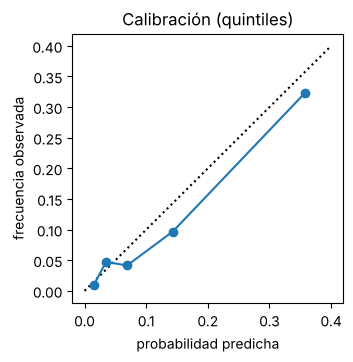

coeficientes: {'vibración': np.float64(0.773), 'temperatura': np.float64(0.145), 'edad': np.float64(0.424), 'carga': np.float64(0.113), 'pendiente': np.float64(-0.237)}


In [24]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)).fit(Xtr, ytr)
for nm, X, y in [("validación", Xva, yva), ("prueba", Xte, yte)]:
    p = clf.predict_proba(X)[:, 1]
    print(f"{nm:10s} AUC {roc_auc_score(y, p):.3f} · pérdida log. {log_loss(y, p):.4f} · Brier {brier_score_loss(y, p):.4f} · tasa {y.mean():.3f}")
p = clf.predict_proba(Xte)[:, 1]; q = np.quantile(p, np.linspace(0, 1, 6))
pred, obsf = [], []
for a, b in zip(q[:-1], q[1:]):
    m = (p >= a) & (p <= b); pred.append(p[m].mean()); obsf.append(yte[m].mean())
plt.figure(figsize=(3.5, 3.5)); plt.plot([0, 0.4], [0, 0.4], "k:"); plt.plot(pred, obsf, "o-")
plt.xlabel("probabilidad predicha"); plt.ylabel("frecuencia observada"); plt.title("Calibración (quintiles)"); plt.show()
print("coeficientes:", dict(zip(["vibración", "temperatura", "edad", "carga", "pendiente"], clf[-1].coef_[0][:5].round(3))))
assert np.isclose(log_loss(yva, clf.predict_proba(Xva)[:, 1]), 0.2455, atol=5e-4)

### 4.2 Weibull con censura y política por edad

Las vidas que terminan en una intervención preventiva están **censuradas**: solo se sabe que la máquina duraba más.

**Ejercicio 8.** Escribe `nll_weibull(theta, tf, tc)` con $\theta=(\ln\beta,\ln\eta)$: menos la log-verosimilitud $\sum_{\text{fallos}}\ln f(t_i)+\sum_{\text{censuras}}\ln R(t_c)$, con $f(t)=\frac{\beta}{\eta}(t/\eta)^{\beta-1}e^{-(t/\eta)^\beta}$ y $R(t)=e^{-(t/\eta)^\beta}$.

In [25]:
def tiempos(F, M, a0):
    t_f, t_c = [], []
    for i in range(NM):
        last = -a0[i]
        for d in range(len(F)):
            if F[d, i]: t_f.append(d + 1 - last); last = d + 1
            elif M[d, i]: t_c.append(d - last); last = d
    return t_f, t_c
tf, tc = [], []
for e, c, F, O, M in H:
    a, b = tiempos(F, M, e.a0); tf += a; tc += b
tf = np.array(tf, float); tc = np.array([x for x in tc if x > 0], float)
print("vidas con avería:", len(tf), "· censuradas:", len(tc))

vidas con avería: 209 · censuradas: 53


In [26]:
# TU CÓDIGO
# --- solución de referencia ---
def nll_weibull(theta, tf, tc):
    b, e = np.exp(theta)
    return -(np.sum(np.log(b / e) + (b - 1) * np.log(tf / e) - (tf / e) ** b) - np.sum((tc / e) ** b))
# --- fin ---

In [27]:
# Comprobación
beta, eta = np.exp(minimize(nll_weibull, [0.5, 4.0], args=(tf, tc), method="Nelder-Mead").x)
b2, _, e2 = stats.weibull_min.fit(tf, floc=0)
assert np.isclose(beta, 2.58, atol=0.01) and np.isclose(eta, 57.6, atol=0.1)
assert b2 > beta and e2 < eta, "Ignorar la censura exagera el desgaste"
print(f"Correcto. Con censura: beta={beta:.3f}, eta={eta:.2f} · ignorándola: beta={b2:.3f}, eta={e2:.2f}")

Correcto. Con censura: beta=2.582, eta=57.62 · ignorándola: beta=3.367, eta=48.00


**Ejercicio 9.** Escribe `tasa_coste(T, beta, eta, cp, cf)` (proposición 4.13): $C(T)=\dfrac{c_pR(T)+c_fF(T)}{\int_0^T R(u)\,du}$, con la integral por la regla del trapecio en 4000 puntos. Calcula el $T^*$ entero entre 5 y 149 días con $c_p=2000$ € y $c_f=9000$ €.

In [28]:
# TU CÓDIGO
# --- solución de referencia ---
def tasa_coste(T, beta, eta, cp, cf, n=4000):
    u = np.linspace(0, T, n); R = np.exp(-(u / eta) ** beta)
    return (cp * R[-1] + cf * (1 - R[-1])) / np.trapezoid(R, u)
Ts = np.arange(5, 150); cr = np.array([tasa_coste(T, beta, eta, CP_F, CF) for T in Ts]); Tstar = int(Ts[cr.argmin()])
# --- fin ---

Correcto. T* = 30 d · 111.64 €/d · con T = 70: 157.31 · sin preventivo: 175.89


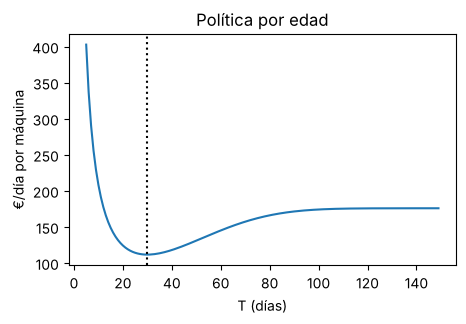

In [29]:
# Comprobación
lam = lambda t: (beta / eta) * (t / eta) ** (beta - 1)
assert Tstar == 30 and np.isclose(cr.min(), 111.64, atol=0.05)
assert np.isclose(cr.min(), (CF - CP_F) * lam(Tstar), rtol=2e-3), "Identidad C(T*) = (cf - cp) λ(T*)"
mtbf = eta * math.gamma(1 + 1 / beta)
print(f"Correcto. T* = {Tstar} d · {cr.min():.2f} €/d · con T = 70: {tasa_coste(70, beta, eta, CP_F, CF):.2f} · sin preventivo: {CF / mtbf:.2f}")
plt.figure(figsize=(5, 3)); plt.plot(Ts, cr); plt.axvline(Tstar, ls=":", c="k"); plt.xlabel("T (días)"); plt.ylabel("€/día por máquina"); plt.title("Política por edad"); plt.show()

### 4.3 Deriva y evaluación contrafactual

**Ejercicio 10.** Escribe `psi(p, q)` (definición 4.5) y `ips(r, pi_nueva, pi_registro)` (proposición 4.9), donde los dos últimos argumentos son las probabilidades de la acción registrada bajo cada política. Comprueba el ejemplo 4.7 y el ejercicio 4.6.

In [30]:
# TU CÓDIGO
# --- solución de referencia ---
def psi(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    return float(np.sum((q - p) * np.log(q / p)))
def ips(r, pi_nueva, pi_registro):
    return float(np.mean(np.asarray(pi_nueva) / np.asarray(pi_registro) * np.asarray(r)))
# --- fin ---

In [31]:
# Comprobación
p_ref, q_rec = [0.25, 0.35, 0.25, 0.15], [0.15, 0.30, 0.30, 0.25]
kl = lambda a, b: float(np.sum(np.asarray(a) * np.log(np.asarray(a) / np.asarray(b))))
assert np.isclose(psi(p_ref, q_rec), 0.119, atol=5e-4) and np.isclose(psi(p_ref, q_rec), kl(p_ref, q_rec) + kl(q_rec, p_ref))
# registros (alarma, acción, coste en miles): política antigua 0,3 / 0,1; nueva: intervenir si y solo si alarma
alarma = np.array([1, 1, 1, 0, 0, 0]); accion = np.array([1, 0, 0, 0, 1, 0]); r = np.array([-1.2, -9, 0, 0, -1.2, 0])
pi0 = np.where(accion == 1, np.where(alarma == 1, 0.3, 0.1), np.where(alarma == 1, 0.7, 0.9))
pi1 = (accion == alarma).astype(float)
assert np.isclose(ips(r, pi1, pi0), -4.0 / 6)
print(f"Correcto. PSI = {psi(p_ref, q_rec):.4f} · IPS política nueva = {ips(r, pi1, pi0):.3f} miles de €")

Correcto. PSI = 0.1190 · IPS política nueva = -0.667 miles de €


### 4.4 El calendario semanal como programa entero

Cada lunes, con $p_{7,i}$, se calcula $\lambda_i=-\ln(1-p_{7,i})/7$ y $F_i(d)=1-e^{-\lambda_i d}$. Variables $x_{iw}$ (intervenir la máquina $i$ en la ventana $w$) e $y_i$ (no intervenir en el horizonte); coste $c_p+c_fF_i(d_w)$ por intervención y $c_fF_i(7\cdot\text{semanas})$ por no intervenir; una intervención por ventana.

**Ejercicio 11.** Escribe `plan(p7, K=1, semanas=2)` con `scipy.optimize.milp`. Devuelve el día de esta semana (0, 2 o 4; −1 si no) para cada máquina, el coste óptimo y la matriz $x$. Comprueba el cuadro 4.1: con una semana, llenadora el lunes, encajonadora el miércoles y coste 6905 €.

In [32]:
# TU CÓDIGO
# --- solución de referencia ---
def plan(p7, K=1, semanas=2, cp=CP_V, cf=CF):
    vent = [7 * s + v for s in range(semanas) for v in VENT]
    lam = -np.log(1 - np.clip(p7, 1e-6, 1 - 1e-6)) / 7
    n, W = len(p7), len(vent); F = lambda d: 1 - np.exp(-lam * d)
    cost = np.concatenate([cp + cf * F(d) for d in vent] + [cf * F(7 * semanas)])   # orden (w, i) y después «no»
    nv = (W + 1) * n; A1 = np.zeros((n, nv)); A2 = np.zeros((W, nv))
    for i in range(n):
        for w in range(W + 1): A1[i, w * n + i] = 1
    for w in range(W): A2[w, w * n:(w + 1) * n] = 1
    res = milp(cost, constraints=[LinearConstraint(A1, 1, 1), LinearConstraint(A2, 0, K)],
               integrality=np.ones(nv), bounds=Bounds(0, 1))
    x = np.round(res.x).reshape(W + 1, n); dia = np.full(n, -1)
    for w in range(W):
        if vent[w] < 7: dia[x[w] == 1] = vent[w]
    return dia, res.fun, x
# --- fin ---

In [33]:
# Comprobación
p7_ej = np.array([0.42, 0.18, 0.07, 0.31, 0.03, 0.12])
dia1, c1, _ = plan(p7_ej, K=1, semanas=1); dia2, c2, x2 = plan(p7_ej, K=1, semanas=2)
assert list(dia1) == [0, -1, -1, 2, -1, -1] and np.isclose(c1, 6905.3, atol=0.1)
assert list(dia2) == [0, 4, -1, 2, -1, -1], "Con dos semanas se añade la taponadora el viernes"
print("Correcto. Una semana:", dict(zip(MAQ, dia1)), f"coste {c1:.1f} € · dos semanas:", dict(zip(MAQ, dia2)))

Correcto. Una semana: {'llenadora': np.int64(0), 'taponadora': np.int64(-1), 'etiquetadora': np.int64(-1), 'encajonadora': np.int64(2), 'paletizadora': np.int64(-1), 'enfardadora': np.int64(-1)} coste 6905.3 € · dos semanas: {'llenadora': np.int64(0), 'taponadora': np.int64(4), 'etiquetadora': np.int64(-1), 'encajonadora': np.int64(2), 'paletizadora': np.int64(-1), 'enfardadora': np.int64(-1)}


### 4.5 Cinco políticas en el gemelo

A: solo correctivo; H: actual (cada 70 días); B: por edad con $T^*$; C: umbral $p_7\ge\theta$ cualquier día ($\theta$ elegido en un año de validación); D: calendario con riesgo y horizonte deslizante de dos semanas. Mismo año de prueba para todas (números aleatorios comunes).

In [34]:
def prob7(obs): return clf.predict_proba(feats(obs[-3:])[-1])[:, 1]
def pol_A(d, obs): return np.zeros(NM, bool)
def pol_B(d, obs): return obs[-1][:, 2] >= Tstar
def make_C(th): return lambda d, obs: prob7(obs) >= th if len(obs) >= 3 else np.zeros(NM, bool)
def make_D(K=1, semanas=2):
    st = {}
    def pol(d, obs):
        if d % 7 == 0: st['dia'] = plan(prob7(obs) if len(obs) >= 3 else np.zeros(NM), K, semanas)[0]
        m = st['dia'] == d % 7
        if m.any(): st['dia'][m] = -1
        return m
    return pol
t0 = time.time()
val = Escenario(364, seed=3)
cv = {th: simula(val, make_C(th))[0].sum() for th in [0.05, 0.1, 0.15, 0.2, 0.3, 0.4]}
theta = min(cv, key=cv.get); print("umbral elegido en validación:", theta)
prueba = Escenario(364, seed=7); W = {}; tabla = {}
for nm, pol in [("A correctivo", pol_A), ("H actual (70 d)", pol_H), (f"B edad ({Tstar} d)", pol_B), (f"C umbral {theta}", make_C(theta)), ("D calendario", make_D())]:
    c, f, o, m = simula(prueba, pol); W[nm[0]] = c.reshape(52, 7).sum(1)
    fuera = int(m[[d % 7 not in VENT for d in range(364)]].sum()); exceso_cap = int((m.sum(1) > 1).sum())
    tabla[nm[0]] = (c.sum(), f.sum(), m.sum(), fuera, exceso_cap)
    print(f"{nm:18s} {c.sum():9.0f} €/año · averías {f.sum():3d} · preventivos {m.sum():3d} · fuera de ventana {fuera:3d} · días con >1 técnico {exceso_cap}")
print(f"({time.time() - t0:.1f} s)")
assert theta == 0.1
assert [tabla[k][0] for k in "AHBCD"] == [360000, 327400, 195200, 173200, 141000]

umbral elegido en validación: 0.1
A correctivo          360000 €/año · averías  40 · preventivos   0 · fuera de ventana   0 · días con >1 técnico 0
H actual (70 d)       327400 €/año · averías  35 · preventivos   7 · fuera de ventana   5 · días con >1 técnico 0
B edad (30 d)         195200 €/año · averías  10 · preventivos  65 · fuera de ventana  34 · días con >1 técnico 0
C umbral 0.1          173200 €/año · averías   6 · preventivos  70 · fuera de ventana  44 · días con >1 técnico 5


D calendario          141000 €/año · averías   7 · preventivos  65 · fuera de ventana   0 · días con >1 técnico 0
(1.3 s)


## Parte 5 · Cuantificar el valor y el riesgo (tema 5)

### 5.1 Intervalos para la mejora
**Ejercicio 12.** Escribe `ic_pareado(d, nivel)` (intervalo $t$) y `ic_bootstrap(d, B, nivel, rng)` (percentil) para la media de las diferencias semanales. Aplícalos a H − D y a B − D.

In [35]:
# TU CÓDIGO
# --- solución de referencia ---
def ic_pareado(d, nivel=0.95):
    d = np.asarray(d, float); n = len(d); m = d.mean(); s = d.std(ddof=1)
    t = stats.t.ppf(0.5 + nivel / 2, n - 1); return m - t * s / np.sqrt(n), m + t * s / np.sqrt(n)
def ic_bootstrap(d, B=10000, nivel=0.95, rng=None):
    rng = rng or np.random.default_rng(0); d = np.asarray(d, float)
    medias = np.array([rng.choice(d, len(d)).mean() for _ in range(B)])
    return tuple(np.percentile(medias, [50 * (1 - nivel), 50 * (1 + nivel)]))
# --- fin ---

In [36]:
# Comprobación
for a in ["H", "B"]:
    d = W[a] - W["D"]; lo, hi = ic_pareado(d); blo, bhi = ic_bootstrap(d, rng=np.random.default_rng(0))
    print(f"{a} − D: media {d.mean():7.1f} €/sem · sd {d.std(ddof=1):6.1f} · IC t [{lo:7.1f}; {hi:7.1f}] · bootstrap [{blo:7.1f}; {bhi:7.1f}] · autocorr. {np.corrcoef(d[:-1], d[1:])[0, 1]:.3f}")
dHD, dBD = W["H"] - W["D"], W["B"] - W["D"]
assert np.allclose(ic_pareado(dHD), (1747.2, 5422.0), atol=0.5) and np.allclose(ic_pareado(dBD), (-170.3, 2254.9), atol=0.5)
assert ic_pareado(dBD)[0] < 0 < ic_pareado(dHD)[0], "Un año basta frente a la práctica actual, no frente a la política por edad"
# ejercicio 5.3 (datos de la lectura 24 de MIT 18.05)
d10 = np.array([30, 37, 36, 43, 42, 43, 43, 46, 41, 42.])
print("ejercicio 5.3, IC t del 80 %:", np.round(ic_pareado(d10, 0.80), 2))

H − D: media  3584.6 €/sem · sd 6599.9 · IC t [ 1747.2;  5422.0] · bootstrap [ 1857.7;  5426.9] · autocorr. -0.303


B − D: media  1042.3 €/sem · sd 4355.6 · IC t [ -170.3;  2254.9] · bootstrap [ -119.2;  2253.9] · autocorr. 0.049
ejercicio 5.3, IC t del 80 %: [38.26 42.34]


### 5.2 Veinte años en el gemelo, tamaño del piloto y CVaR

In [37]:
t0 = time.time(); R20 = []
for sd in range(100, 120):
    e = Escenario(364, seed=sd); R20.append([simula(e, p)[0].sum() for p in (pol_H, pol_B, make_D())])
R20 = np.array(R20); dBD20 = R20[:, 1] - R20[:, 2]
print(f"medias H, B, D: {R20.mean(0).round(0)} · B − D: {dBD20.mean():.0f} ± {dBD20.std(ddof=1):.0f} €/año · IC 95 % {np.round(ic_pareado(dBD20), 0)} · ({time.time() - t0:.1f} s)")
assert np.isclose(dBD20.mean(), 34370) and np.isclose(R20[:, 2].mean(), 159300)

medias H, B, D: [330290. 193670. 159300.] · B − D: 34370 ± 13637 €/año · IC 95 % [27987. 40753.] · (7.4 s)


**Ejercicio 13.** Escribe `tamano_piloto(sigma, delta, alpha=0.05, potencia=0.8)` (proposición 5.5) y `cvar(costes, alpha)` como la media de los $\lceil(1-\alpha)n\rceil$ peores escenarios.

In [38]:
# TU CÓDIGO
# --- solución de referencia ---
def tamano_piloto(sigma, delta, alpha=0.05, potencia=0.8):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(potencia)
    return int(math.ceil((z * sigma / delta) ** 2))
def cvar(costes, alpha):
    c = np.sort(np.asarray(costes, float)); k = int(math.ceil((1 - alpha) * len(c) - 1e-9))
    return float(c[-k:].mean())
# --- fin ---

In [39]:
# Comprobación
n_sem = tamano_piloto(4355.6, 34370 / 52)
assert n_sem == 341 and tamano_piloto(3.1, 0.9) == 94
assert cvar([152, 148, 171, 160, 139, 183, 157, 166, 149, 175], 0.8) == 179
print(f"Correcto. Semanas necesarias: {n_sem} · CVaR90 B = {cvar(R20[:, 1], 0.9):.0f} € · CVaR90 D = {cvar(R20[:, 2], 0.9):.0f} €")
assert cvar(R20[:, 2], 0.9) == 186300 and cvar(R20[:, 1], 0.9) == 216200

Correcto. Semanas necesarias: 341 · CVaR90 B = 216200 € · CVaR90 D = 186300 €


### 5.3 Valor actual neto con incertidumbre

**Ejercicio 14.** Escribe `van(I, flujo, rho, N)` para un flujo neto anual constante. Calcula el VAN del optimizador frente a la política por edad ($I=48\,000$ €, operación 9000 €/año, 5 años, 8 %) y, con Monte Carlo (100 000 simulaciones), la probabilidad de VAN negativo con beneficios anuales $\mathcal N(34\,370;\ 13\,637^2)$ independientes, sobrecoste de la inversión $U(0;\,30\,\%)$ y operación entre $-10\,\%$ y $+30\,\%$.

In [40]:
# TU CÓDIGO
# --- solución de referencia ---
def van(I, flujo, rho, N):
    return -I + flujo * (1 - (1 + rho) ** -N) / rho
rng = np.random.default_rng(0); Nmc = 100000
ben = rng.normal(34370, 13637, (Nmc, 5)); inv = 48000 * (1 + rng.uniform(0, 0.3, Nmc)); opx = 9000 * (1 + rng.uniform(-0.1, 0.3, Nmc))
van_mc = ((ben - opx[:, None]) * 1.08 ** -np.arange(1, 6)).sum(1) - inv
# --- fin ---

Correcto. VAN = 53295 € · TIR = 44.5 % · Monte Carlo: media 42568 €, P(VAN<0) = 0.046


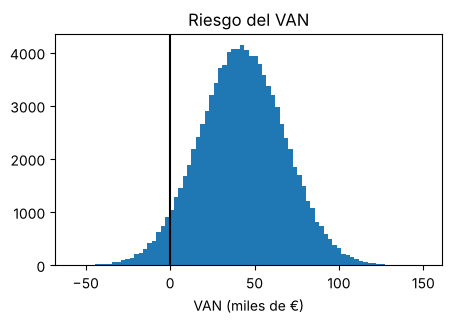

In [41]:
# Comprobación
assert np.isclose(van(48000, 34370 - 9000, 0.08, 5), 53295, atol=1)
assert np.isclose(van_mc.mean(), 42568, atol=50) and np.isclose((van_mc < 0).mean(), 0.0457, atol=0.002)
tir = brentq(lambda r: van(48000, 25370, r, 5), 0.001, 1)
print(f"Correcto. VAN = {van(48000, 25370, 0.08, 5):.0f} € · TIR = {100 * tir:.1f} % · Monte Carlo: media {van_mc.mean():.0f} €, P(VAN<0) = {(van_mc < 0).mean():.3f}")
plt.figure(figsize=(5, 3)); plt.hist(van_mc / 1000, bins=80); plt.axvline(0, c="k"); plt.xlabel("VAN (miles de €)"); plt.title("Riesgo del VAN"); plt.show()

## Parte 6 · La guía: techo de valor y mini-casos (tema 6)

### 6.1 Techo de valor con un oráculo
Una política que conoce el futuro interviene cada máquina en la última ventana antes de que fuera a fallar (sin límite de técnicos). Su coste indica cuánto podría ganarse prediciendo mejor (proposición 6.1).

In [42]:
def oraculo(esc, dias=364):
    h = esc.h0.copy(); coste = 0.0
    vent_dias = [d for d in range(dias) if d % 7 in VENT]
    for d in range(dias):
        if d % 7 in VENT:
            nxt = next((v for v in vent_dias if v > d), dias)
            for i in range(NM):
                hh = h[i]
                for k in range(d, nxt):
                    hh += esc.g[k, i] * RATE[i] * (0.6 + 0.8 * esc.load[k])
                    if esc.u[k, i] < hazard(hh):
                        h[i] = 0; coste += CP_V; break
        h += esc.g[d] * RATE * (0.6 + 0.8 * esc.load[d])
        f = esc.u[d] < hazard(h); coste += CF * f.sum(); h[f] = 0
    return coste
c_or = np.mean([oraculo(Escenario(364, seed=s)) for s in range(100, 120)])
H_, B_, D_ = R20.mean(0)
print(f"oráculo {c_or:.0f} €/año · fracción del margen B → oráculo que captura D: {(B_ - D_) / (B_ - c_or):.3f}")
assert np.isclose(c_or, 76170) and np.isclose((B_ - D_) / (B_ - c_or), 0.2925, atol=1e-3)

oráculo 76170 €/año · fracción del margen B → oráculo que captura D: 0.293


### 6.2 Mini-casos A (fábrica) y B (videojuego)

**Ejercicio 15.** (a) Escribe `mejor_ciclo(M, nombres)` que enumere los ciclos que empiezan por el primer formato y devuelva el de menor tiempo de cambio. (b) Escribe `mejor_lod(objs, presupuesto, fijos)` que enumere las combinaciones de niveles de detalle, respete el presupuesto de triángulos y los niveles fijados, y devuelva la de menor error.

In [43]:
M_cambio = np.array([[0, 20, 45, 40], [25, 0, 35, 45], [60, 55, 0, 30], [90, 90, 90, 0]])   # A, B, C, D (soja)
objs = {"personaje": [(60, 0.0), (25, 1.0), (10, 4.0)], "edificio": [(80, 0.0), (30, 0.6), (12, 2.5)], "árboles": [(50, 0.0), (15, 0.8), (5, 3.0)]}
# TU CÓDIGO
# --- solución de referencia ---
def mejor_ciclo(M, nombres="ABCD"):
    n = len(nombres); best = None
    for perm in itertools.permutations(range(1, n)):
        s = (0,) + perm; t = sum(M[a, b] for a, b in zip(s, s[1:] + s[:1]))
        if best is None or t < best[0]: best = (t, "".join(nombres[i] for i in s))
    return best
def mejor_lod(objs, presupuesto, fijos=None):
    fijos = fijos or {}; nombres = list(objs); best = None
    for c in itertools.product(*[range(len(objs[k])) for k in nombres]):
        if any(c[nombres.index(k)] != v for k, v in fijos.items()): continue
        tri = sum(objs[k][c[i]][0] for i, k in enumerate(nombres)); err = sum(objs[k][c[i]][1] for i, k in enumerate(nombres))
        if tri <= presupuesto and (best is None or err < best[0] - 1e-12): best = (round(err, 6), tri, c)
    return best
# --- fin ---

In [44]:
# Comprobación
assert mejor_ciclo(M_cambio) == (175, "ABCD")
assert mejor_lod(objs, 100) == (2.4, 70, (1, 1, 1)) and mejor_lod(objs, 100, {"personaje": 0}) == (3.3, 87, (0, 2, 1))
assert mejor_lod(objs, 105)[2][0] == 0, "Con 105 000 triángulos la regla del personaje ya no cuesta nada"
print("Correcto. Ciclo óptimo:", mejor_ciclo(M_cambio), "· LOD sin regla:", mejor_lod(objs, 100), "· con regla:", mejor_lod(objs, 100, {"personaje": 0}))
print(f"Tiempo total de ejecución: {time.time() - T_INICIO:.1f} s")

Correcto. Ciclo óptimo: (np.int64(175), 'ABCD') · LOD sin regla: (2.4, 70, (1, 1, 1)) · con regla: (3.3, 87, (0, 2, 1))
Tiempo total de ejecución: 71.1 s


## Parte 7 · Retos

1. **Más evaluador, menos sobreajuste.** Entrena la búsqueda de la parte 1 con una mezcla de instancias Weibull de escalas 35, 45 y 60. ¿Pierde algo en escala 45? ¿Gana en escala 60?
2. **Simplificar el programa.** Escribe una función que pode del árbol ganador los subárboles cuya eliminación no cambie las bandejas en entrenamiento, y compara las longitudes.
3. **Evaluación en cascada.** Al estilo de AlphaEvolve, evalúa primero cada programa con 200 objetos y solo si no es peor que el mejor en más de un 2 % con las 3000. ¿Cuánto tiempo se ahorra y cuánta calidad se pierde?
4. **OPRO con presupuesto.** Repite la parte 2.2 con 48 y 192 evaluaciones y con 50 y 400 ejemplos de validación. Representa la exactitud verdadera y el optimismo.
5. **Hyperband.** Sustituye el halving de la parte 3 por varias rondas con distinta fracción inicial (1/27, 1/9, 1/3) y compara coste y resultado.
6. **Capacidad 2.** Repite la parte 4.5 con dos técnicos por ventana. ¿Por qué no mejora necesariamente? (pista: el plan es miope respecto a lo que pasa después de dos semanas).
7. **Reentrenar dentro del bucle.** Reentrena el clasificador con los datos generados bajo la política D y compara sus coeficientes con los originales (observación 4.3).
8. **Bootstrap por bloques.** Recalcula los intervalos de la parte 5.1 remuestreando bloques de 4 semanas.

---
### Comentarios a las soluciones de referencia
Inténtalo antes de leer.

* **Ej. 1.** FF y BF son prioridades: todo el conocimiento sobre factibilidad está en el esqueleto, que solo ofrece candidatos donde el objeto cabe más una bandeja vacía. Con `argmax`, los empates se resuelven a favor del primer candidato; por eso FF es simplemente «menos el índice».
* **Ej. 2.** La temperatura solo tiene sentido relativa a la escala de las puntuaciones: normalizar por el rango hace que $T=0{,}3$ signifique lo mismo en cualquier problema.
* **Ej. 3.** La regla evita dejar restos de 10 a 20 unidades, que casi ningún paquete puede aprovechar; con huecos mayores que 20 se comporta como FF. No es *any fit*: puede abrir una bandeja nueva teniendo sitio (ejercicio 1.7).
* **Ej. 4.** El sesgo simulado (≈ 0,083) queda por debajo de la cota $\sigma\sqrt{2\ln K}$ (0,112), que no usa la independencia.
* **Ej. 5.** Como $\Delta_m$ decrece, basta parar en el primer $m$ con $V\Delta_m<2c$; la comprobación lo confirma por fuerza bruta.
* **Ej. 6.** La media geométrica de los inversos es el inverso de la media geométrica; la aritmética no.
* **Ej. 7.** El halving cuesta 9 entrenamientos completos equivalentes frente a 27, aunque el tiempo de reloj no baja en la misma proporción por los costes fijos.
* **Ej. 8.** La censura importa: ignorarla da $\beta\approx3{,}37$ en lugar de $2{,}58$.
* **Ej. 9.** En el óptimo se cumple $C(T^*)=(c_f-c_p)\lambda(T^*)$ (proposición 4.13); la pequeña diferencia se debe a que $T$ es entero.
* **Ej. 10.** En la ponderación inversa, los registros incompatibles con la política nueva pesan cero; aquí la estimación descansa en un único registro con alarma e intervención.
* **Ej. 11.** El problema es de transporte: aunque se declaren variables enteras, la relajación lineal ya da soluciones enteras.
* **Ej. 12.** Frente a la práctica actual, un año basta; frente a la política por edad, no (proposición 5.5: harían falta unas 341 semanas).
* **Ej. 13–14.** El VAN frente a la alternativa sencilla es positivo pero modesto, y el riesgo de VAN negativo ronda el 5 %.
* **Ej. 15.** Con pocos elementos, enumerar es la forma más segura de comprobar un PLEM; con muchos, se formula y se resuelve (ejercicio 6.6).